# Experiment 3: Regression Analysis using Linear and Regularized Models

## 1. Import Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings
warnings.filterwarnings('ignore')

from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12

## 2. Load Dataset

In [4]:
df = pd.read_csv('train.csv')
print(f"Dataset loaded: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()

Dataset loaded: 30000 rows, 24 columns


,Customer ID,Name,Gender,Age,Income (USD),Income Stability,Profession,Type of Employment,Location,Loan Amount Request (USD),...,Credit Score,No. of Defaults,Has Active Credit Card,Property ID,Property Age,Property Type,Property Location,Co-Applicant,Property Price,Loan Sanction Amount (USD)
0,C-36995,Frederica Shealy,F,56,1933.05,Low,Working,Sales staff,Semi-Urban,72809.58,...,809.44,0,NaN,746,1933.05,4,Rural,1,119933.46,54607.18
1,C-33999,America Calderone,M,32,4952.91,Low,Working,NaN,Semi-Urban,46837.47,...,780.40,0,Unpossessed,608,4952.91,2,Rural,1,54791.00,37469.98
2,C-3770,Rosetta Verne,F,65,988.19,High,Pensioner,NaN,Semi-Urban,45593.04,...,833.15,0,Unpossessed,546,988.19,2,Urban,0,72440.58,36474.43
3,C-26480,Zoe Chitty,F,65,NaN,High,Pensioner,NaN,Rural,80057.92,...,832.70,1,Unpossessed,890,NaN,2,Semi-Urban,1,121441.51,56040.54
4,C-23459,Afton Venema,F,31,2614.77,Low,Working,High skill tech staff,Semi-Urban,113858.89,...,745.55,1,Active,715,2614.77,4,Semi-Urban,1,208567.91,74008.28


## 3. Dataset Information

In [5]:
print("Shape:", df.shape)
print("\nColumn Data Types:")
print(df.dtypes)
print("\nDataset Info:")
df.info()

Shape: (30000, 24)

Column Data Types:
Customer ID                     object
Name                            object
Gender                          object
Age                              int64
Income (USD)                   float64
Income Stability                object
Profession                      object
Type of Employment              object
Location                        object
Loan Amount Request (USD)      float64
Current Loan Expenses (USD)    float64
Expense Type 1                  object
Expense Type 2                  object
Dependents                     float64
Credit Score                   float64
No. of Defaults                  int64
Has Active Credit Card          object
Property ID                      int64
Property Age                   float64
Property Type                    int64
Property Location               object
Co-Applicant                     int64
Property Price                 float64
Loan Sanction Amount (USD)     float64
dtype: object

Dataset In

In [6]:
print("Statistical Summary:")
df.describe(include='all')

Statistical Summary:


,Customer ID,Name,Gender,Age,Income (USD),Income Stability,Profession,Type of Employment,Location,Loan Amount Request (USD),...,Credit Score,No. of Defaults,Has Active Credit Card,Property ID,Property Age,Property Type,Property Location,Co-Applicant,Property Price,Loan Sanction Amount (USD)
count,30000,30000,29947,30000.000000,2.542400e+04,28317,30000,22730,30000,30000.000000,...,28297.000000,30000.000000,28434,30000.000000,2.515000e+04,30000.000000,29644,30000.000000,3.000000e+04,29660.000000
unique,30000,30000,2,NaN,NaN,2,8,18,3,NaN,...,NaN,NaN,3,NaN,NaN,NaN,3,NaN,NaN,NaN
top,C-45413,Marilou Kwiecien,M,NaN,NaN,Low,Working,Laborers,Semi-Urban,NaN,...,NaN,NaN,Active,NaN,NaN,NaN,Semi-Urban,NaN,NaN,NaN
freq,1,1,15053,NaN,NaN,25751,16926,5578,21563,NaN,...,NaN,NaN,9771,NaN,NaN,NaN,10387,NaN,NaN,NaN
mean,NaN,NaN,NaN,40.092300,2.630574e+03,NaN,NaN,NaN,NaN,88826.333855,...,739.885381,0.193933,NaN,501.934700,2.631119e+03,2.460067,NaN,-4.743867,1.317597e+05,47649.342208
std,NaN,NaN,NaN,16.045129,1.126272e+04,NaN,NaN,NaN,NaN,59536.949605,...,72.163846,0.395384,NaN,288.158086,1.132268e+04,1.118562,NaN,74.614593,9.354955e+04,48221.146686
min,NaN,NaN,NaN,18.000000,3.777000e+02,NaN,NaN,NaN,NaN,6048.240000,...,580.000000,0.000000,NaN,1.000000,3.777000e+02,1.000000,NaN,-999.000000,-9.990000e+02,-999.000000
25%,NaN,NaN,NaN,25.000000,1.650457e+03,NaN,NaN,NaN,NaN,41177.755000,...,681.880000,0.000000,NaN,251.000000,1.650450e+03,1.000000,NaN,1.000000,6.057216e+04,0.000000
50%,NaN,NaN,NaN,40.000000,2.222435e+03,NaN,NaN,NaN,NaN,75128.075000,...,739.820000,0.000000,NaN,504.000000,2.223250e+03,2.000000,NaN,1.000000,1.099936e+05,35209.395000
75%,NaN,NaN,NaN,55.000000,3.090593e+03,NaN,NaN,NaN,NaN,119964.605000,...,799.120000,0.000000,NaN,751.000000,3.091408e+03,3.000000,NaN,1.000000,1.788807e+05,74261.250000


## 4. Missing Value Analysis

In [7]:
missing_summary = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage': (df.isnull().sum() / len(df)) * 100
})
missing_summary = missing_summary[missing_summary['Missing Count'] > 0].sort_values('Missing Count', ascending=False)
print("Missing Value Summary:")
print(missing_summary if not missing_summary.empty else "No missing values found.")

Missing Value Summary:
                             Missing Count  Missing Percentage
Type of Employment                    7270           24.233333
Property Age                          4850           16.166667
Income (USD)                          4576           15.253333
Dependents                            2493            8.310000
Credit Score                          1703            5.676667
Income Stability                      1683            5.610000
Has Active Credit Card                1566            5.220000
Property Location                      356            1.186667
Loan Sanction Amount (USD)             340            1.133333
Current Loan Expenses (USD)            172            0.573333
Gender                                  53            0.176667


## 5. Duplicate Value Check

In [8]:
duplicate_count = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicate_count}")
if duplicate_count > 0:
    df = df.drop_duplicates()
    print(f"Duplicates removed. New shape: {df.shape}")

Number of duplicate rows: 0


## 6. Data Preprocessing

In [9]:
target_col = 'LoanAmount' if 'LoanAmount' in df.columns else df.select_dtypes(include=np.number).columns[-1]
print(f"Target column: {target_col}")

numerical_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

if target_col in numerical_cols:
    numerical_cols.remove(target_col)

print(f"Numerical features: {numerical_cols}")
print(f"Categorical features: {categorical_cols}")

Target column: Loan Sanction Amount (USD)
Numerical features: ['Age', 'Income (USD)', 'Loan Amount Request (USD)', 'Current Loan Expenses (USD)', 'Dependents', 'Credit Score', 'No. of Defaults', 'Property ID', 'Property Age', 'Property Type', 'Co-Applicant', 'Property Price']
Categorical features: ['Customer ID', 'Name', 'Gender', 'Income Stability', 'Profession', 'Type of Employment', 'Location', 'Expense Type 1', 'Expense Type 2', 'Has Active Credit Card', 'Property Location']


In [10]:
for col in numerical_cols + [target_col]:
    df[col].fillna(df[col].median(), inplace=True)

for col in categorical_cols:
    df[col].fillna(df[col].mode()[0], inplace=True)

print("Missing values after handling:", df.isnull().sum().sum())

Missing values after handling: 0


## 7. Exploratory Data Analysis (EDA)

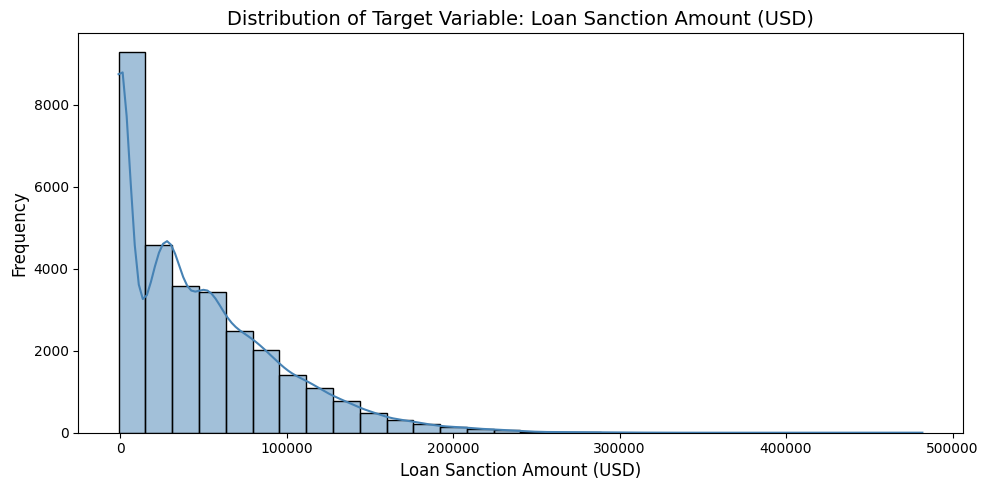

In [11]:
plt.figure(figsize=(10, 5))
sns.histplot(df[target_col], kde=True, bins=30, color='steelblue')
plt.title(f'Distribution of Target Variable: {target_col}')
plt.xlabel(target_col)
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

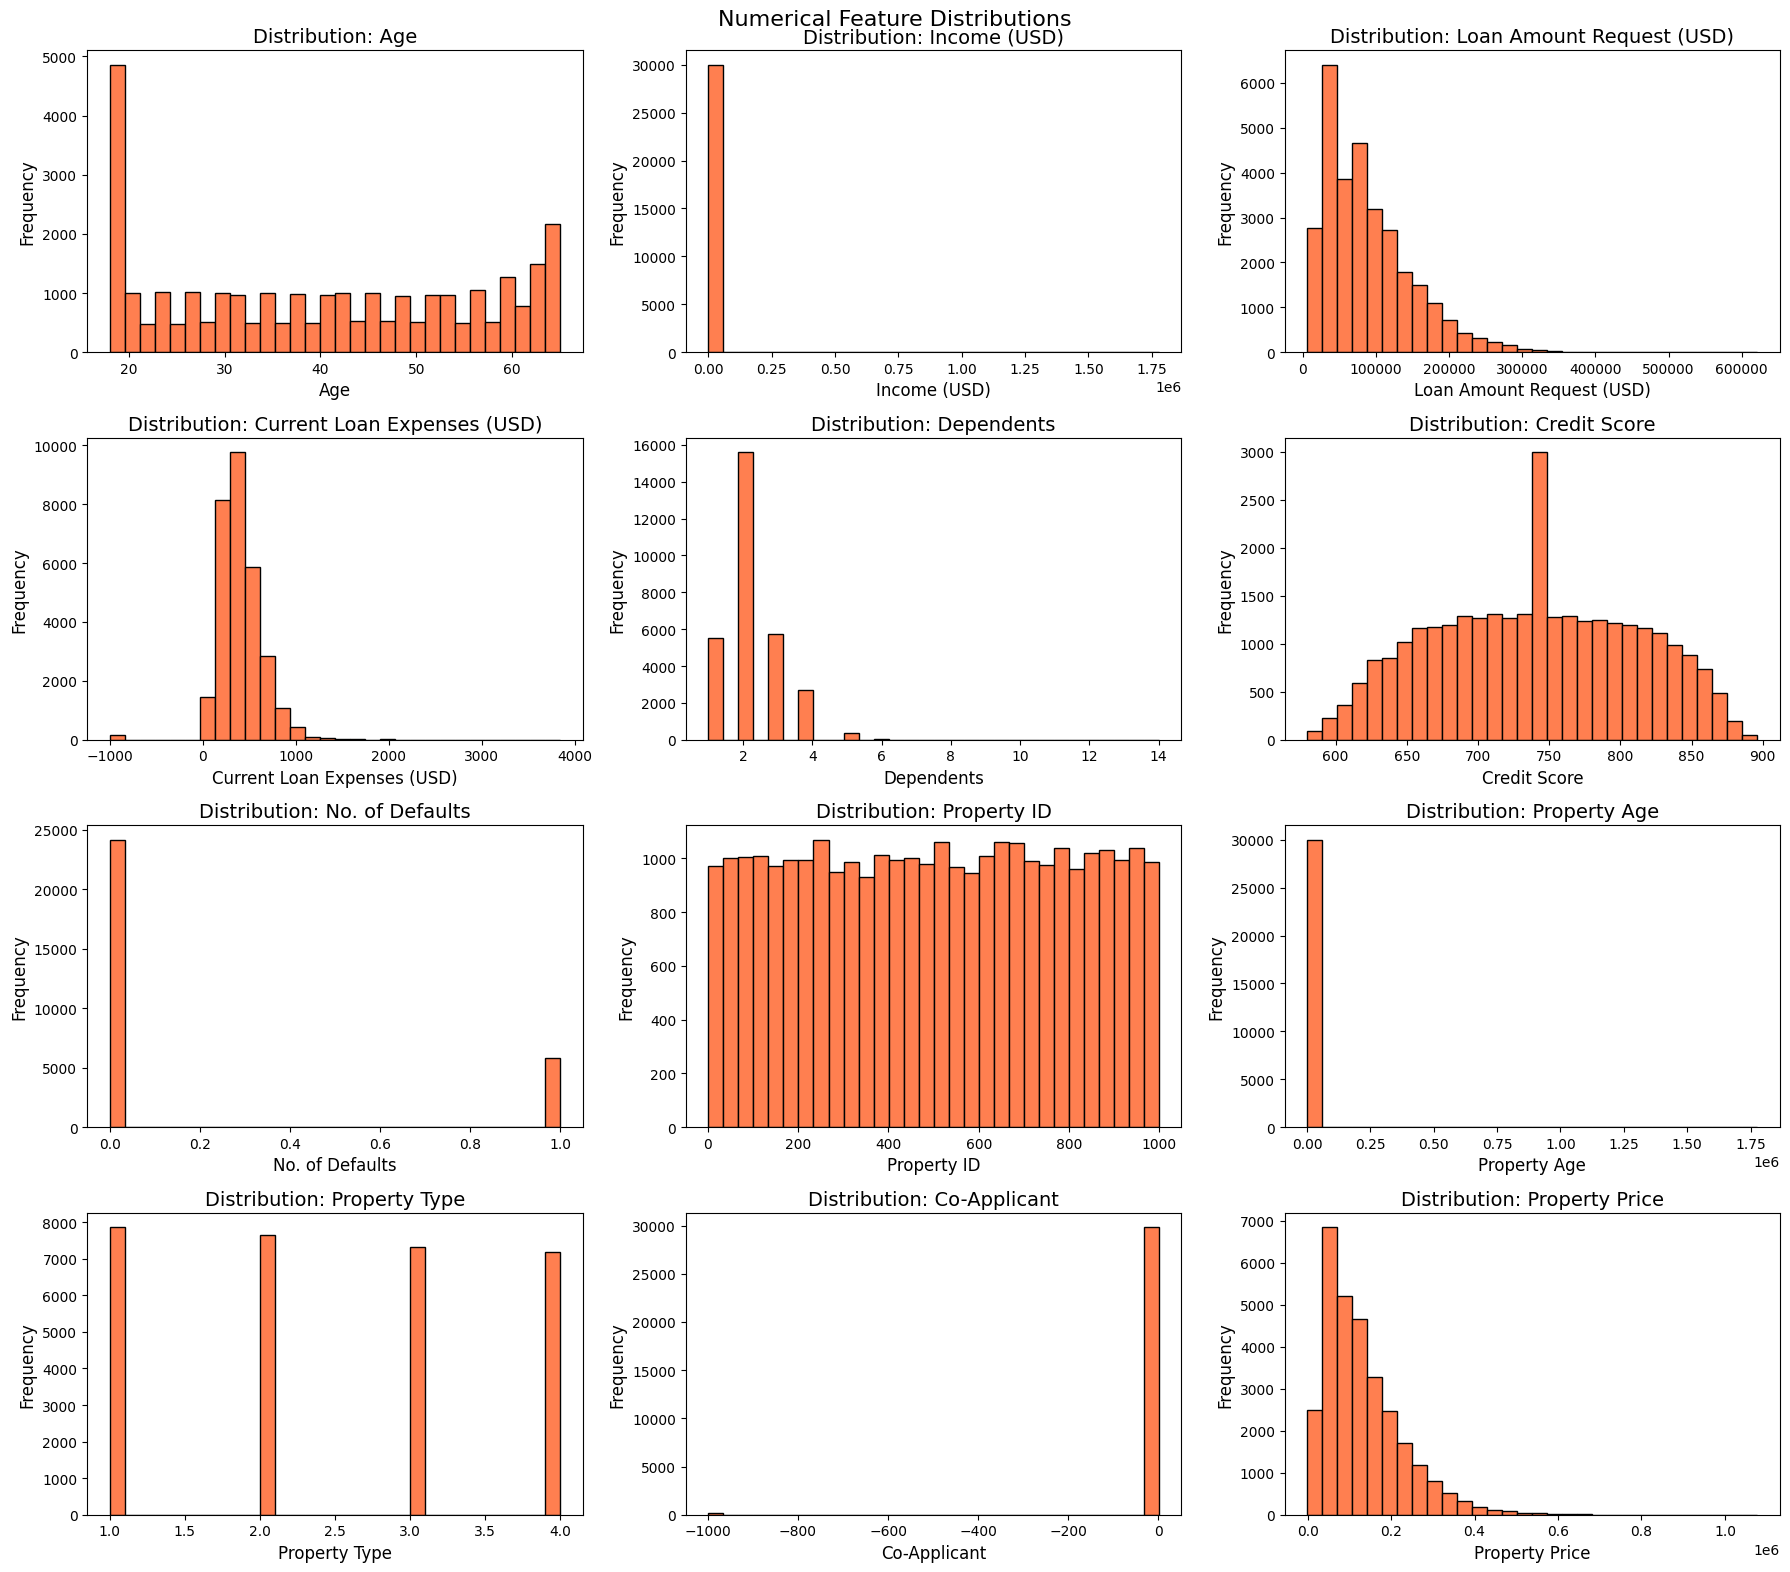

In [12]:
if numerical_cols:
    n_cols = 3
    n_rows = int(np.ceil(len(numerical_cols) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 4))
    axes = axes.flatten()
    for i, col in enumerate(numerical_cols):
        axes[i].hist(df[col].dropna(), bins=30, color='coral', edgecolor='black')
        axes[i].set_title(f'Distribution: {col}')
        axes[i].set_xlabel(col)
        axes[i].set_ylabel('Frequency')
    for j in range(i + 1, len(axes)):
        axes[j].set_visible(False)
    plt.suptitle('Numerical Feature Distributions', fontsize=16)
    plt.tight_layout()
    plt.show()

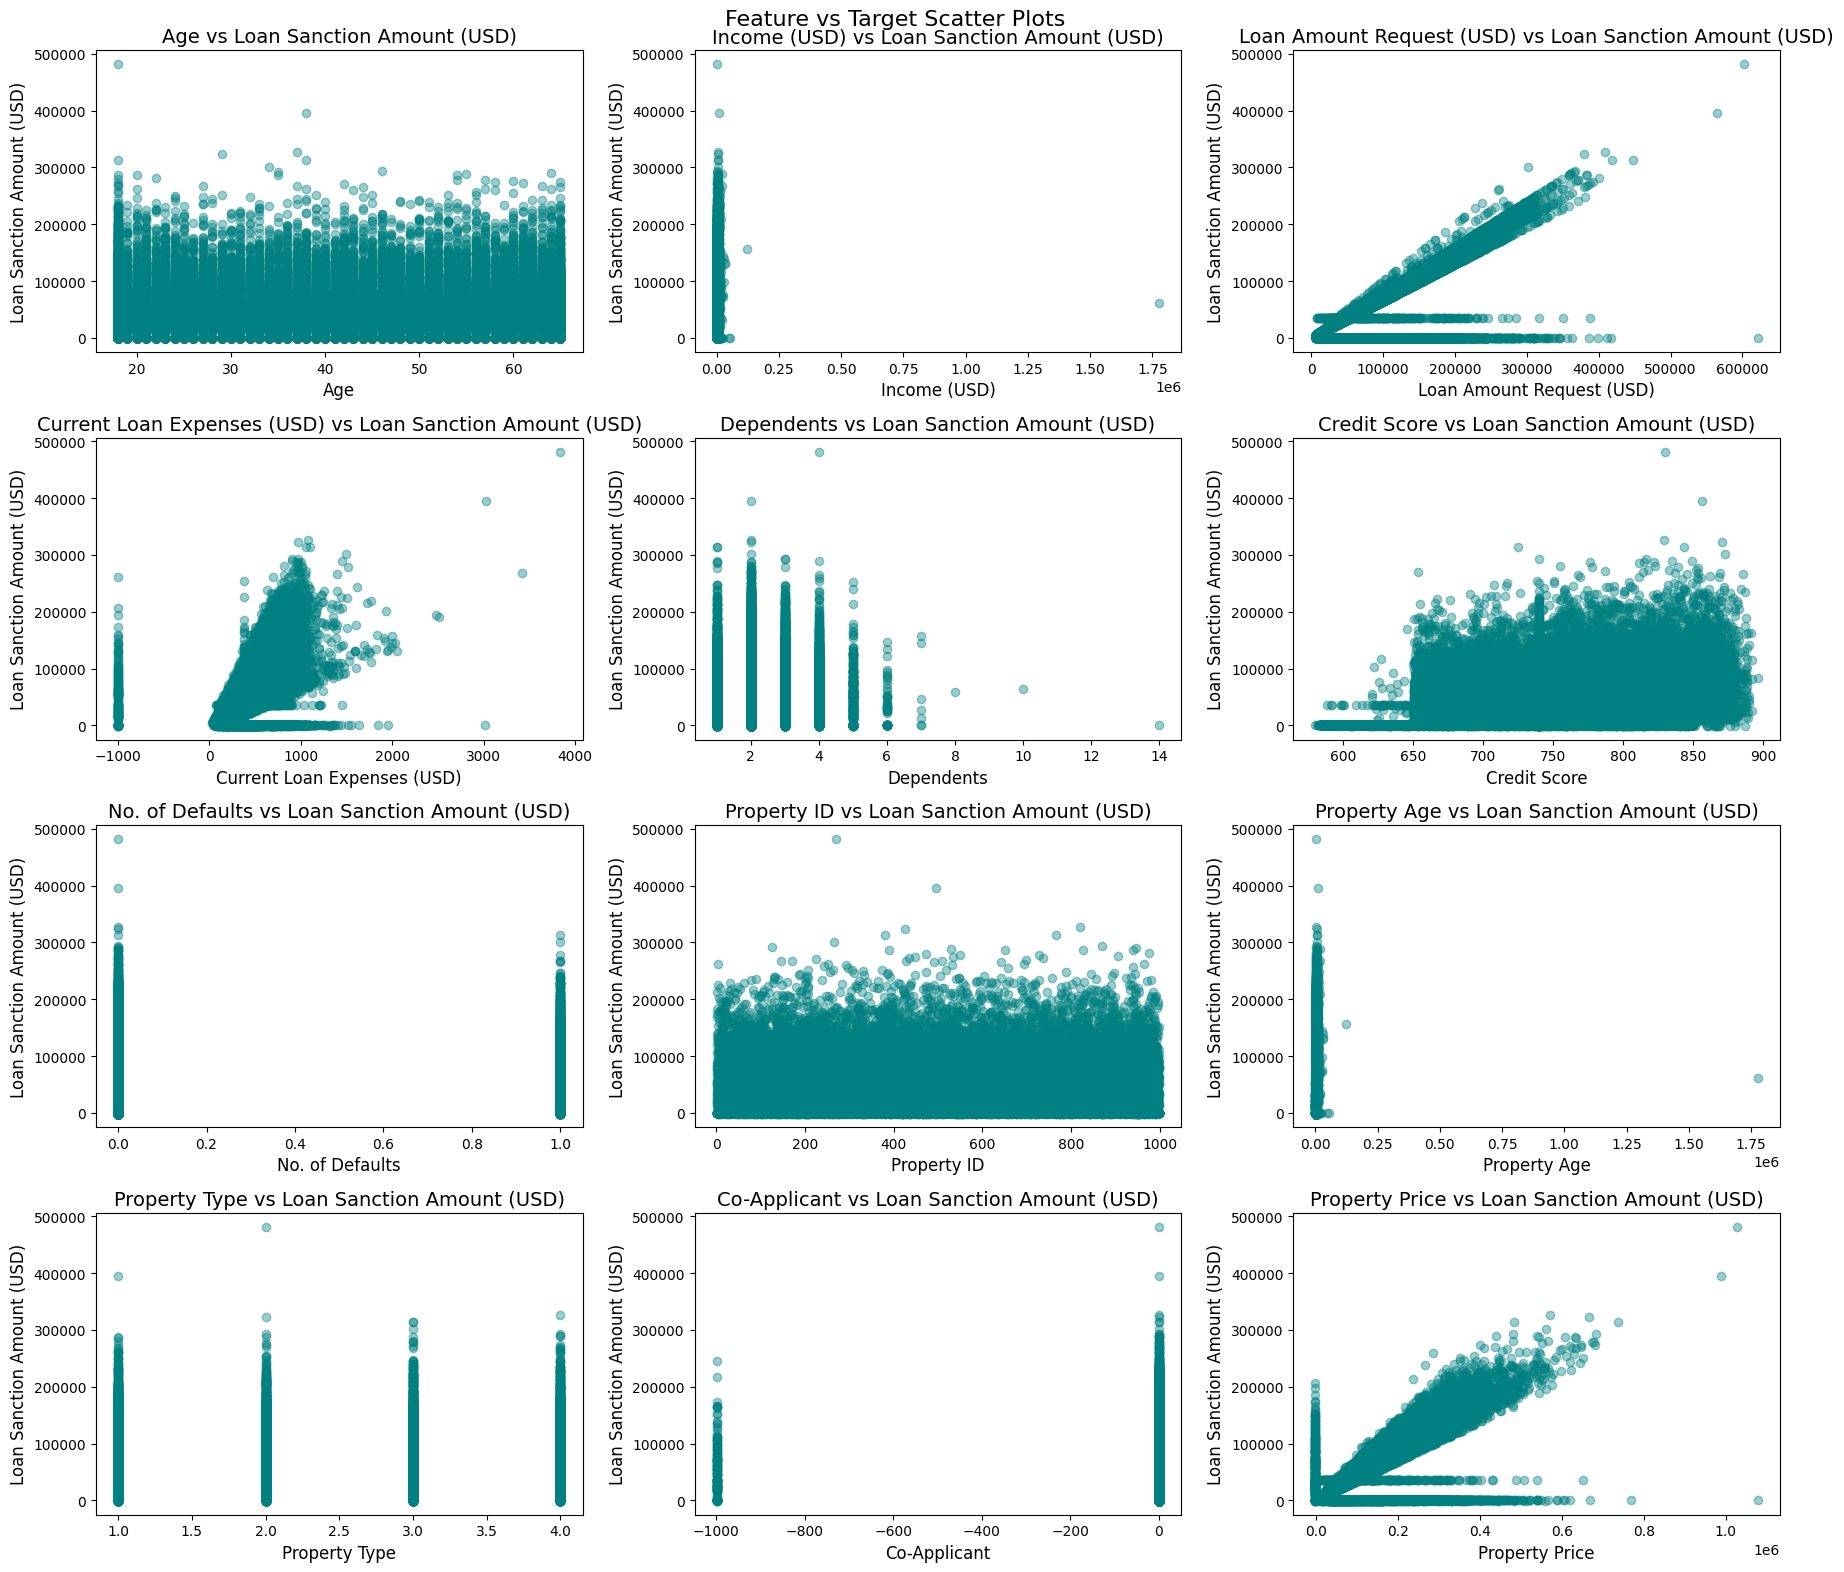

In [13]:
if numerical_cols:
    n_cols = 3
    n_rows = int(np.ceil(len(numerical_cols) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 4))
    axes = axes.flatten()
    for i, col in enumerate(numerical_cols):
        axes[i].scatter(df[col], df[target_col], alpha=0.4, color='teal')
        axes[i].set_title(f'{col} vs {target_col}')
        axes[i].set_xlabel(col)
        axes[i].set_ylabel(target_col)
    for j in range(i + 1, len(axes)):
        axes[j].set_visible(False)
    plt.suptitle('Feature vs Target Scatter Plots', fontsize=16)
    plt.tight_layout()
    plt.show()

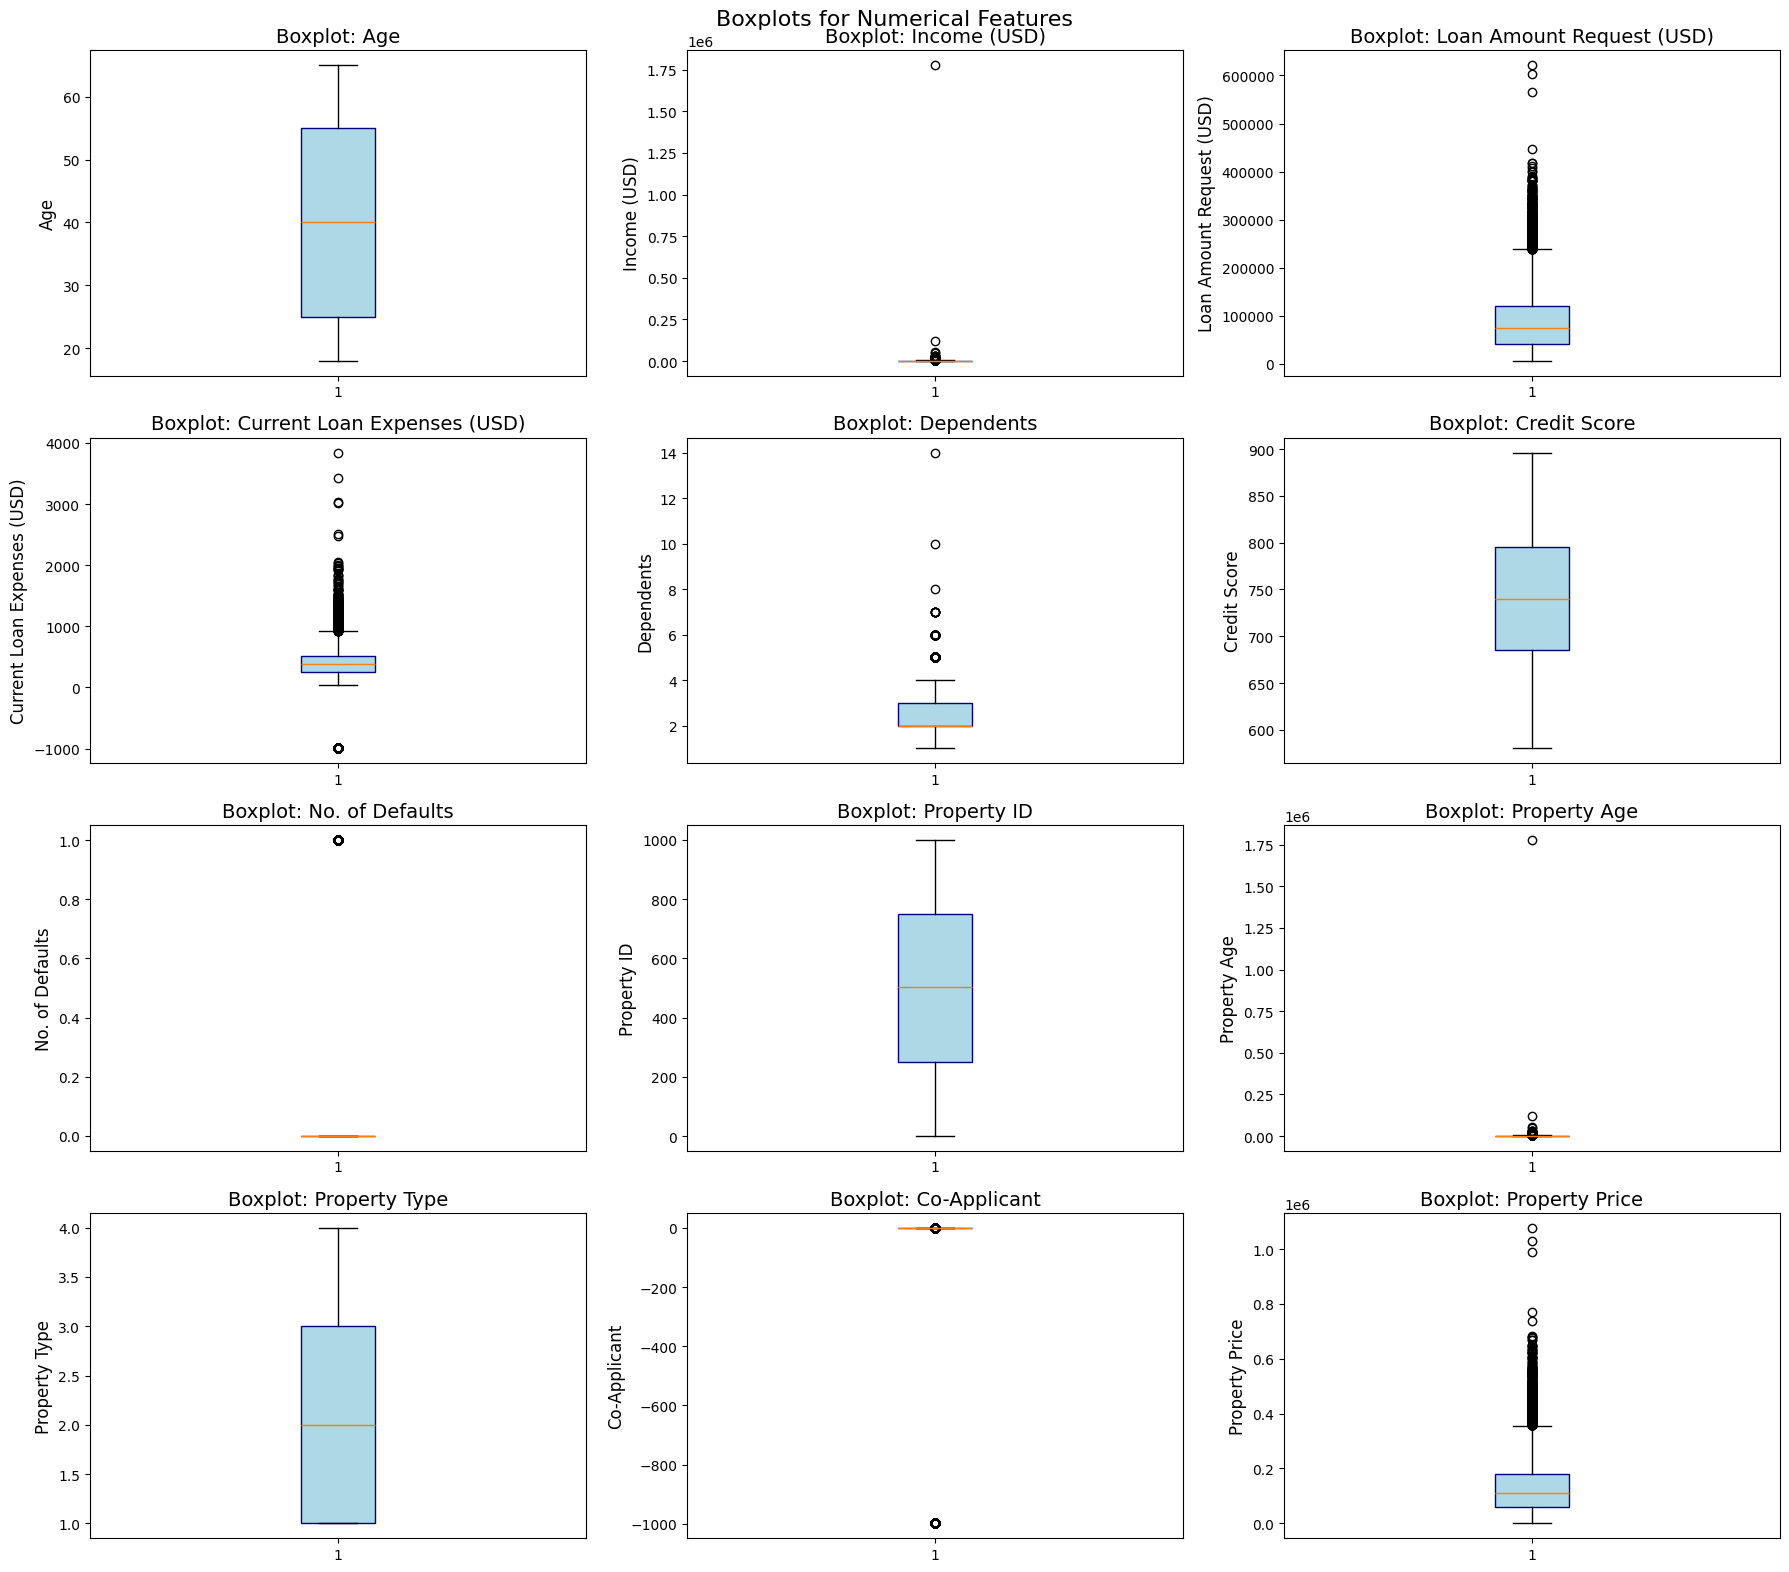

In [14]:
if numerical_cols:
    n_cols = 3
    n_rows = int(np.ceil(len(numerical_cols) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 4))
    axes = axes.flatten()
    for i, col in enumerate(numerical_cols):
        axes[i].boxplot(df[col].dropna(), patch_artist=True,
                        boxprops=dict(facecolor='lightblue', color='navy'))
        axes[i].set_title(f'Boxplot: {col}')
        axes[i].set_ylabel(col)
    for j in range(i + 1, len(axes)):
        axes[j].set_visible(False)
    plt.suptitle('Boxplots for Numerical Features', fontsize=16)
    plt.tight_layout()
    plt.show()

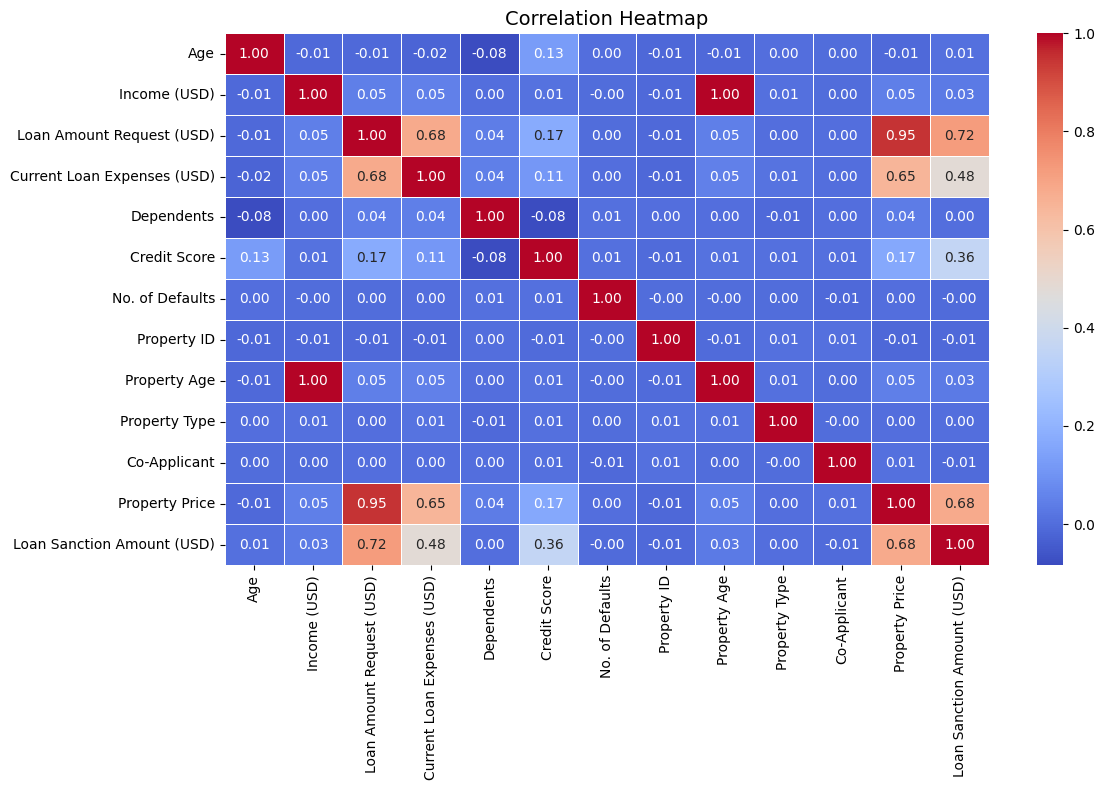

In [15]:
corr_cols = numerical_cols + [target_col]
corr_matrix = df[corr_cols].corr()
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

## 8. Feature Encoding

In [16]:
df_encoded = df.copy()

for col in categorical_cols:
    if df_encoded[col].nunique() <= 5:
        dummies = pd.get_dummies(df_encoded[col], prefix=col, drop_first=True)
        df_encoded = pd.concat([df_encoded.drop(columns=[col]), dummies], axis=1)
    else:
        le = LabelEncoder()
        df_encoded[col] = le.fit_transform(df_encoded[col].astype(str))

bool_cols = df_encoded.select_dtypes(include='bool').columns.tolist()
df_encoded[bool_cols] = df_encoded[bool_cols].astype(int)

print(f"Shape after encoding: {df_encoded.shape}")
df_encoded.head()

Shape after encoding: (30000, 27)


,Customer ID,Name,Age,Income (USD),Profession,Type of Employment,Loan Amount Request (USD),Current Loan Expenses (USD),Dependents,Credit Score,...,Gender_M,Income Stability_Low,Location_Semi-Urban,Location_Urban,Expense Type 1_Y,Expense Type 2_Y,Has Active Credit Card_Inactive,Has Active Credit Card_Unpossessed,Property Location_Semi-Urban,Property Location_Urban
0,18080,9529,56,1933.050,7,14,72809.58,241.08,3.0,809.44,...,0,1,1,0,0,0,0,0,0,0
1,16076,1304,32,4952.910,7,8,46837.47,495.81,1.0,780.40,...,1,1,1,0,0,1,0,1,0,0
2,18552,24595,65,988.190,3,8,45593.04,171.95,1.0,833.15,...,0,0,1,0,0,1,0,1,0,1
3,11046,29860,65,2222.435,3,8,80057.92,298.54,2.0,832.70,...,0,0,0,0,0,1,0,1,1,0
4,8991,190,31,2614.770,7,6,113858.89,491.41,2.0,745.55,...,0,1,1,0,0,1,0,0,1,0


## 9. Feature Scaling

In [17]:
X = df_encoded.drop(columns=[target_col])
y = df_encoded[target_col]

feature_names = X.columns.tolist()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=feature_names)

print(f"Features shape: {X_scaled.shape}")
print(f"Target shape: {y.shape}")

Features shape: (30000, 26)
Target shape: (30000,)


## 10. Train-Test Split

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)
print(f"Training set: {X_train.shape}")
print(f"Test set:     {X_test.shape}")

Training set: (24000, 26)
Test set:     (6000, 26)


## 11. Baseline Linear Regression

In [19]:
def evaluate_model(model, X_test, y_test, train_time):
    y_pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    return {'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R2': r2, 'Training Time': train_time, 'y_pred': y_pred}

start = time.time()
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
lr_time = time.time() - start

lr_results = evaluate_model(lr_model, X_test, y_test, lr_time)

print("Linear Regression Results:")
for k, v in lr_results.items():
    if k != 'y_pred':
        print(f"  {k}: {v:.4f}")

Linear Regression Results:
  MAE: 20783.4528
  MSE: 960900997.0039
  RMSE: 30998.4031
  R2: 0.5823
  Training Time: 0.0537


## 12. Linear Regression Evaluation

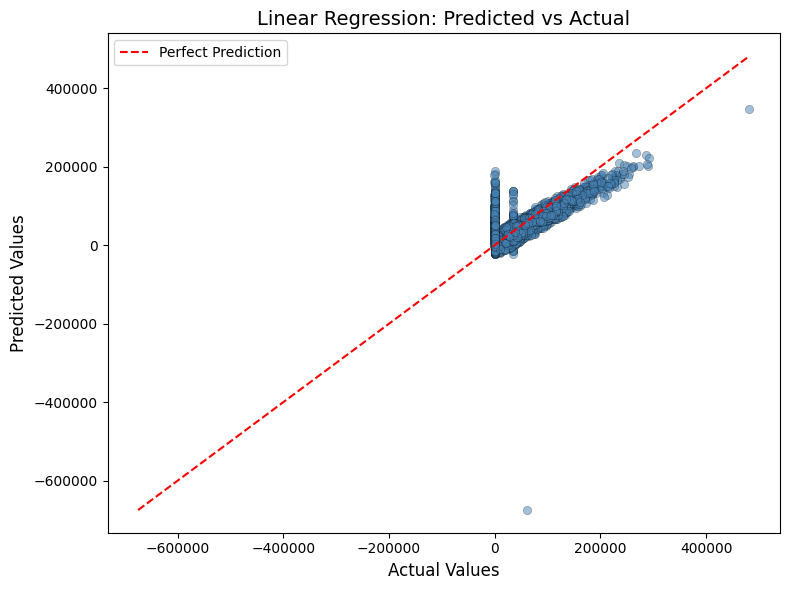

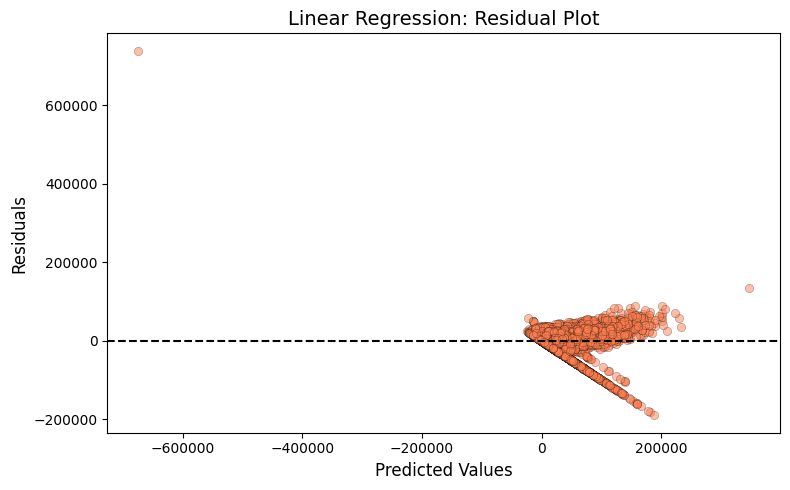

In [20]:
def plot_predicted_vs_actual(y_test, y_pred, title):
    plt.figure(figsize=(8, 6))
    plt.scatter(y_test, y_pred, alpha=0.5, color='steelblue', edgecolors='k', linewidths=0.3)
    min_val = min(y_test.min(), y_pred.min())
    max_val = max(y_test.max(), y_pred.max())
    plt.plot([min_val, max_val], [min_val, max_val], 'r--', label='Perfect Prediction')
    plt.xlabel('Actual Values')
    plt.ylabel('Predicted Values')
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.show()

def plot_residuals(y_test, y_pred, title):
    residuals = y_test - y_pred
    plt.figure(figsize=(8, 5))
    plt.scatter(y_pred, residuals, alpha=0.5, color='coral', edgecolors='k', linewidths=0.3)
    plt.axhline(0, color='black', linestyle='--')
    plt.xlabel('Predicted Values')
    plt.ylabel('Residuals')
    plt.title(title)
    plt.tight_layout()
    plt.show()

plot_predicted_vs_actual(y_test, lr_results['y_pred'], 'Linear Regression: Predicted vs Actual')
plot_residuals(y_test, lr_results['y_pred'], 'Linear Regression: Residual Plot')

## 13. Ridge Regression

In [21]:
ridge_params = {'alpha': [0.01, 0.1, 1, 10, 100]}
ridge_grid = GridSearchCV(Ridge(random_state=42), ridge_params, cv=5, scoring='r2', n_jobs=-1)

start = time.time()
ridge_grid.fit(X_train, y_train)
ridge_time = time.time() - start

print(f"Ridge Best Parameters: {ridge_grid.best_params_}")
print(f"Ridge Best CV R²: {ridge_grid.best_score_:.4f}")

ridge_model = ridge_grid.best_estimator_
ridge_results = evaluate_model(ridge_model, X_test, y_test, ridge_time)

print("\nRidge Regression Results:")
for k, v in ridge_results.items():
    if k != 'y_pred':
        print(f"  {k}: {v:.4f}")

Ridge Best Parameters: {'alpha': 0.01}
Ridge Best CV R²: 0.6068

Ridge Regression Results:
  MAE: 20783.4309
  MSE: 960887497.7379
  RMSE: 30998.1854
  R2: 0.5823
  Training Time: 7.3628


## 14. Lasso Regression

In [22]:
lasso_params = {'alpha': [0.001, 0.01, 0.1, 1, 10]}
lasso_grid = GridSearchCV(Lasso(random_state=42, max_iter=10000), lasso_params, cv=5, scoring='r2', n_jobs=-1)

start = time.time()
lasso_grid.fit(X_train, y_train)
lasso_time = time.time() - start

print(f"Lasso Best Parameters: {lasso_grid.best_params_}")
print(f"Lasso Best CV R²: {lasso_grid.best_score_:.4f}")

lasso_model = lasso_grid.best_estimator_
lasso_results = evaluate_model(lasso_model, X_test, y_test, lasso_time)

print("\nLasso Regression Results:")
for k, v in lasso_results.items():
    if k != 'y_pred':
        print(f"  {k}: {v:.4f}")

Lasso Best Parameters: {'alpha': 0.001}
Lasso Best CV R²: 0.6068

Lasso Regression Results:
  MAE: 20783.4509
  MSE: 960900080.4083
  RMSE: 30998.3884
  R2: 0.5823
  Training Time: 16.9388


## 15. Elastic Net Regression

In [23]:
enet_params = {'alpha': [0.01, 0.1, 1, 10], 'l1_ratio': [0.2, 0.5, 0.8]}
enet_grid = GridSearchCV(ElasticNet(random_state=42, max_iter=10000), enet_params, cv=5, scoring='r2', n_jobs=-1)

start = time.time()
enet_grid.fit(X_train, y_train)
enet_time = time.time() - start

print(f"Elastic Net Best Parameters: {enet_grid.best_params_}")
print(f"Elastic Net Best CV R²: {enet_grid.best_score_:.4f}")

enet_model = enet_grid.best_estimator_
enet_results = evaluate_model(enet_model, X_test, y_test, enet_time)

print("\nElastic Net Regression Results:")
for k, v in enet_results.items():
    if k != 'y_pred':
        print(f"  {k}: {v:.4f}")

Elastic Net Best Parameters: {'alpha': 0.01, 'l1_ratio': 0.8}
Elastic Net Best CV R²: 0.6067

Elastic Net Regression Results:
  MAE: 20789.0637
  MSE: 949589596.6066
  RMSE: 30815.4117
  R2: 0.5872
  Training Time: 2.7309


## 16. Hyperparameter Tuning Summary

In [24]:
tuning_summary = pd.DataFrame([
    {'Model': 'Ridge Regression',    'Search Method': 'GridSearchCV', 'Best Parameters': str(ridge_grid.best_params_), 'Best CV R²': ridge_grid.best_score_},
    {'Model': 'Lasso Regression',    'Search Method': 'GridSearchCV', 'Best Parameters': str(lasso_grid.best_params_), 'Best CV R²': lasso_grid.best_score_},
    {'Model': 'Elastic Net Regression', 'Search Method': 'GridSearchCV', 'Best Parameters': str(enet_grid.best_params_), 'Best CV R²': enet_grid.best_score_},
])
tuning_summary['Best CV R²'] = tuning_summary['Best CV R²'].round(4)
print("Table 1: Hyperparameter Tuning Summary")
tuning_summary

Table 1: Hyperparameter Tuning Summary


,Model,Search Method,Best Parameters,Best CV R²
0,Ridge Regression,GridSearchCV,{'alpha': 0.01},0.6068
1,Lasso Regression,GridSearchCV,{'alpha': 0.001},0.6068
2,Elastic Net Regression,GridSearchCV,"{'alpha': 0.01, 'l1_ratio': 0.8}",0.6067


## 17. Best Model Evaluation

In [25]:
test_perf = pd.DataFrame([
    {'Model': 'Linear Regression',    'MAE': lr_results['MAE'],    'MSE': lr_results['MSE'],    'RMSE': lr_results['RMSE'],    'R²': lr_results['R2'],    'Training Time (s)': lr_results['Training Time']},
    {'Model': 'Ridge Regression',     'MAE': ridge_results['MAE'], 'MSE': ridge_results['MSE'], 'RMSE': ridge_results['RMSE'], 'R²': ridge_results['R2'], 'Training Time (s)': ridge_results['Training Time']},
    {'Model': 'Lasso Regression',     'MAE': lasso_results['MAE'], 'MSE': lasso_results['MSE'], 'RMSE': lasso_results['RMSE'], 'R²': lasso_results['R2'], 'Training Time (s)': lasso_results['Training Time']},
    {'Model': 'Elastic Net Regression','MAE': enet_results['MAE'], 'MSE': enet_results['MSE'], 'RMSE': enet_results['RMSE'], 'R²': enet_results['R2'], 'Training Time (s)': enet_results['Training Time']},
])
for col in ['MAE', 'MSE', 'RMSE', 'R²', 'Training Time (s)']:
    test_perf[col] = test_perf[col].round(4)
print("Table 3: Test Set Performance")
test_perf

Table 3: Test Set Performance


,Model,MAE,MSE,RMSE,R²,Training Time (s)
0,Linear Regression,20783.4528,9.609010e+08,30998.4031,0.5823,0.0537
1,Ridge Regression,20783.4309,9.608875e+08,30998.1854,0.5823,7.3628
2,Lasso Regression,20783.4509,9.609001e+08,30998.3884,0.5823,16.9388
3,Elastic Net Regression,20789.0637,9.495896e+08,30815.4117,0.5872,2.7309


## 18. Cross Validation

In [26]:
def cv_metrics(model, X, y, cv=5):
    mae_scores  = -cross_val_score(model, X, y, cv=cv, scoring='neg_mean_absolute_error')
    mse_scores  = -cross_val_score(model, X, y, cv=cv, scoring='neg_mean_squared_error')
    r2_scores   =  cross_val_score(model, X, y, cv=cv, scoring='r2')
    rmse_scores = np.sqrt(mse_scores)
    print(f"  Fold R² scores: {np.round(r2_scores, 4)}")
    print(f"  Average R²: {r2_scores.mean():.4f}")
    return {'MAE': mae_scores.mean(), 'MSE': mse_scores.mean(),
            'RMSE': rmse_scores.mean(), 'R²': r2_scores.mean()}

print("Linear Regression CV:")
lr_cv = cv_metrics(LinearRegression(), X_scaled, y)

print("\nRidge Regression CV:")
ridge_cv = cv_metrics(Ridge(**ridge_grid.best_params_, random_state=42), X_scaled, y)

print("\nLasso Regression CV:")
lasso_cv = cv_metrics(Lasso(**lasso_grid.best_params_, random_state=42, max_iter=10000), X_scaled, y)

print("\nElastic Net Regression CV:")
enet_cv  = cv_metrics(ElasticNet(**enet_grid.best_params_, random_state=42, max_iter=10000), X_scaled, y)

Linear Regression CV:
  Fold R² scores: [0.5934 0.6034 0.6037 0.5848 0.6356]
  Average R²: 0.6042

Ridge Regression CV:
  Fold R² scores: [0.5934 0.6034 0.6037 0.5848 0.6356]
  Average R²: 0.6042

Lasso Regression CV:
  Fold R² scores: [0.5934 0.6034 0.6037 0.5848 0.6356]
  Average R²: 0.6042

Elastic Net Regression CV:
  Fold R² scores: [0.5934 0.6034 0.6034 0.5885 0.6358]
  Average R²: 0.6049


In [27]:
cv_summary = pd.DataFrame([
    {'Model': 'Linear Regression',     **lr_cv},
    {'Model': 'Ridge Regression',      **ridge_cv},
    {'Model': 'Lasso Regression',      **lasso_cv},
    {'Model': 'Elastic Net Regression',**enet_cv},
])
for col in ['MAE', 'MSE', 'RMSE', 'R²']:
    cv_summary[col] = cv_summary[col].round(4)
print("Table 2: Cross-Validation Performance (K=5)")
cv_summary

Table 2: Cross-Validation Performance (K=5)


,Model,MAE,MSE,RMSE,R²
0,Linear Regression,20894.3202,9.099291e+08,30159.8037,0.6042
1,Ridge Regression,20894.3078,9.099262e+08,30159.7578,0.6042
2,Lasso Regression,20893.9553,9.099202e+08,30159.6482,0.6042
3,Elastic Net Regression,20901.6515,9.082456e+08,30132.6019,0.6049


## 19. Model Comparison

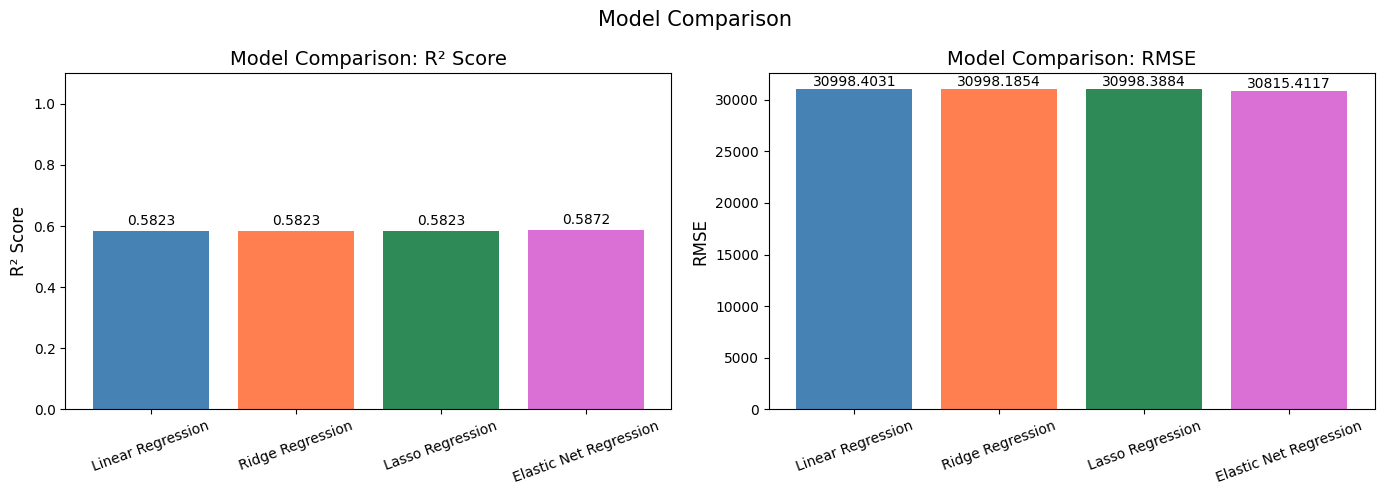

In [28]:
model_names = test_perf['Model'].tolist()
r2_scores_list   = test_perf['R²'].tolist()
rmse_scores_list = test_perf['RMSE'].tolist()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

bars1 = axes[0].bar(model_names, r2_scores_list, color=['steelblue', 'coral', 'seagreen', 'orchid'])
axes[0].set_title('Model Comparison: R² Score')
axes[0].set_ylabel('R² Score')
axes[0].set_ylim(0, 1.1)
axes[0].tick_params(axis='x', rotation=20)
for bar, val in zip(bars1, r2_scores_list):
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01, f'{val:.4f}', ha='center', va='bottom', fontsize=10)

bars2 = axes[1].bar(model_names, rmse_scores_list, color=['steelblue', 'coral', 'seagreen', 'orchid'])
axes[1].set_title('Model Comparison: RMSE')
axes[1].set_ylabel('RMSE')
axes[1].tick_params(axis='x', rotation=20)
for bar, val in zip(bars2, rmse_scores_list):
    axes[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01, f'{val:.4f}', ha='center', va='bottom', fontsize=10)

plt.suptitle('Model Comparison', fontsize=15)
plt.tight_layout()
plt.show()

## 20. Coefficient Comparison

In [29]:
coef_df = pd.DataFrame({
    'Feature':      feature_names,
    'Linear':       lr_model.coef_,
    'Ridge':        ridge_model.coef_,
    'Lasso':        lasso_model.coef_,
    'Elastic Net':  enet_model.coef_,
})
print("Table 4: Coefficient Comparison")
coef_df

Table 4: Coefficient Comparison


,Feature,Linear,Ridge,Lasso,Elastic Net
0,Customer ID,-8801.119261,-8801.136406,-8801.120007,-8791.222910
1,Name,-11.838021,-11.850139,-11.837976,-16.384532
2,Age,-557.375377,-557.350062,-557.372556,-549.726280
3,Income (USD),27829.850985,27709.716511,27820.220373,-475.661523
4,Profession,-64.976099,-64.978922,-64.974873,-64.998064
5,Type of Employment,191.818979,191.825552,191.818442,189.561773
6,Loan Amount Request (USD),33583.795429,33583.654411,33583.775459,32876.204720
7,Current Loan Expenses (USD),-272.469581,-272.415464,-272.463239,-188.481126
8,Dependents,-237.107936,-237.096983,-237.105813,-230.703452
9,Credit Score,11840.762261,11840.740603,11840.759397,11819.940699


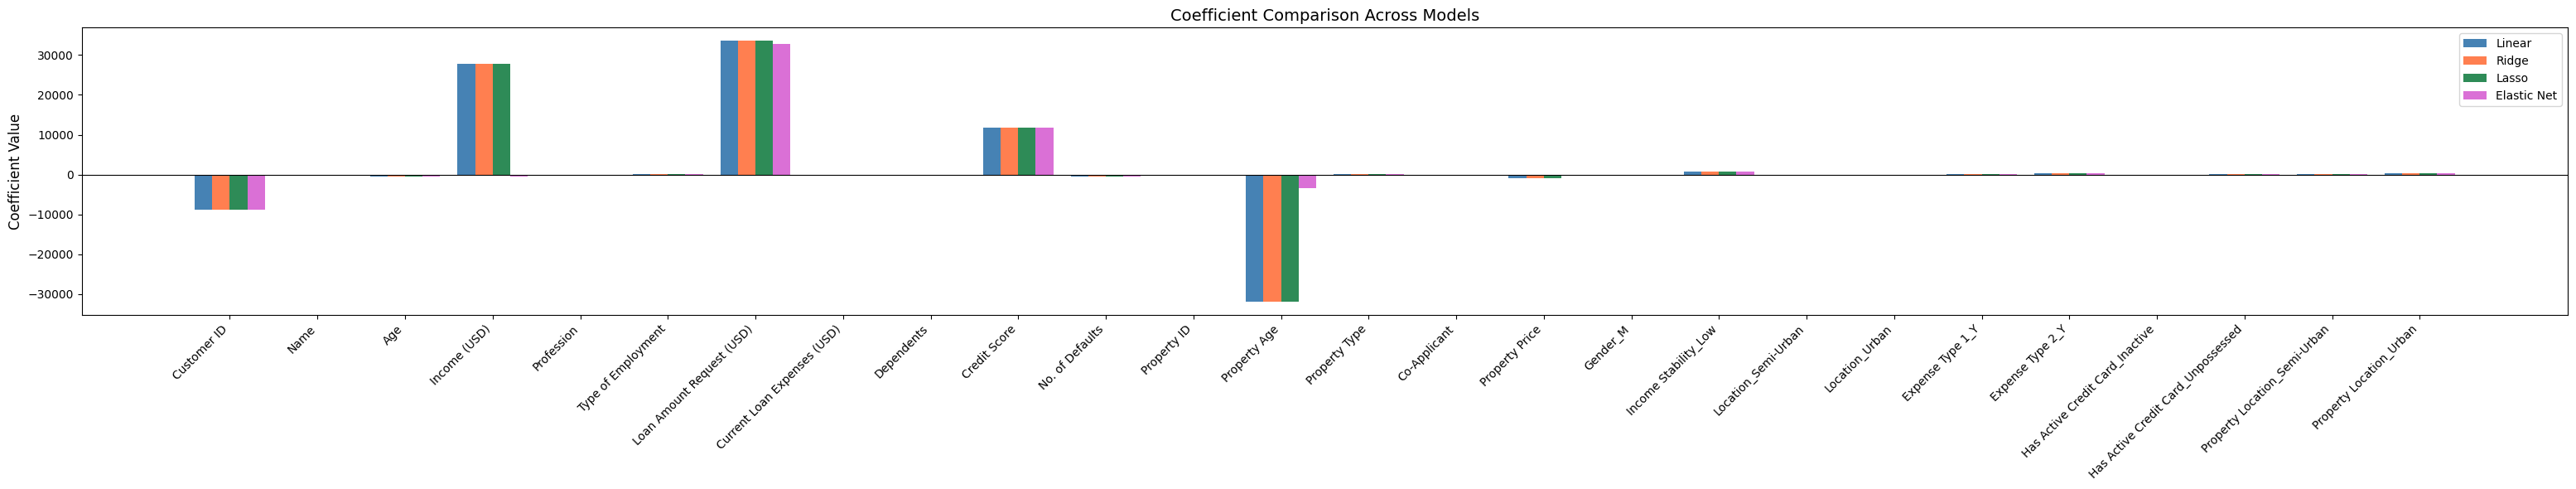

In [30]:
x = np.arange(len(feature_names))
width = 0.2

fig, ax = plt.subplots(figsize=(max(12, len(feature_names) * 1.2), 6))
ax.bar(x - 1.5 * width, coef_df['Linear'],     width, label='Linear',      color='steelblue')
ax.bar(x - 0.5 * width, coef_df['Ridge'],      width, label='Ridge',       color='coral')
ax.bar(x + 0.5 * width, coef_df['Lasso'],      width, label='Lasso',       color='seagreen')
ax.bar(x + 1.5 * width, coef_df['Elastic Net'],width, label='Elastic Net', color='orchid')

ax.set_xticks(x)
ax.set_xticklabels(feature_names, rotation=45, ha='right')
ax.set_title('Coefficient Comparison Across Models')
ax.set_ylabel('Coefficient Value')
ax.axhline(0, color='black', linewidth=0.8)
ax.legend()
plt.tight_layout()
plt.show()

## 21. Overfitting and Underfitting Analysis

Linear          | Train RMSE: 30028.0875 | Val RMSE: 30998.4031 | Diff: 970.3156
Ridge           | Train RMSE: 30028.0876 | Val RMSE: 30998.1854 | Diff: 970.0978
Lasso           | Train RMSE: 30028.0875 | Val RMSE: 30998.3884 | Diff: 970.3008
Elastic Net     | Train RMSE: 30031.6791 | Val RMSE: 30815.4117 | Diff: 783.7325


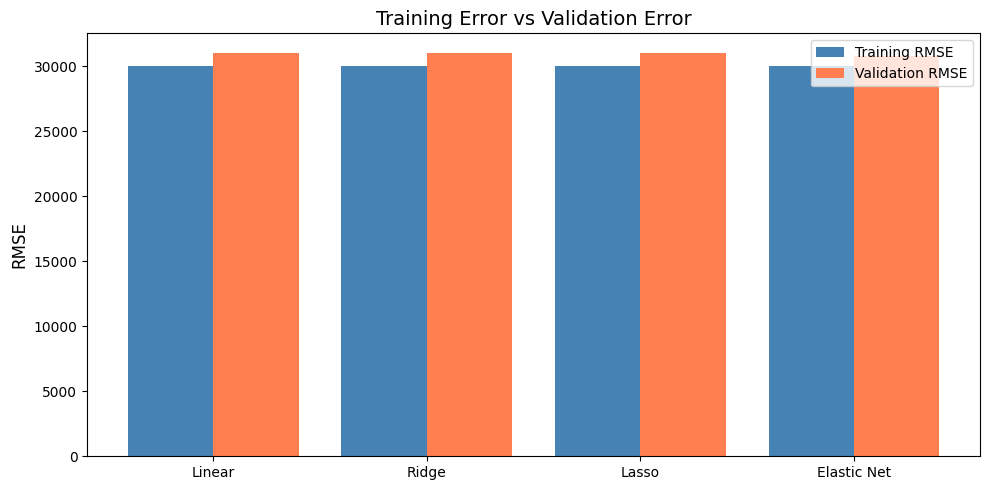

In [31]:
def train_val_errors(model, X_train, y_train, X_test, y_test):
    train_rmse = np.sqrt(mean_squared_error(y_train, model.predict(X_train)))
    val_rmse   = np.sqrt(mean_squared_error(y_test,  model.predict(X_test)))
    return train_rmse, val_rmse

models_dict = {
    'Linear':      lr_model,
    'Ridge':       ridge_model,
    'Lasso':       lasso_model,
    'Elastic Net': enet_model,
}

train_errors, val_errors = [], []
for name, m in models_dict.items():
    tr, va = train_val_errors(m, X_train, y_train, X_test, y_test)
    train_errors.append(tr)
    val_errors.append(va)
    print(f"{name:15s} | Train RMSE: {tr:.4f} | Val RMSE: {va:.4f} | Diff: {abs(va - tr):.4f}")

x_pos = np.arange(len(models_dict))
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x_pos - 0.2, train_errors, 0.4, label='Training RMSE', color='steelblue')
ax.bar(x_pos + 0.2, val_errors,   0.4, label='Validation RMSE', color='coral')
ax.set_xticks(x_pos)
ax.set_xticklabels(list(models_dict.keys()))
ax.set_title('Training Error vs Validation Error')
ax.set_ylabel('RMSE')
ax.legend()
plt.tight_layout()
plt.show()

## 22. Bias–Variance Analysis

In [36]:
zero_coef_lasso = np.sum(lasso_model.coef_ == 0)
total_features = len(feature_names)

print("Bias–Variance Analysis:")
print(f"\n  Linear Regression:")
print(f"    - Train R²: {r2_score(y_train, lr_model.predict(X_train)):.4f}, Test R²: {lr_results['R2']:.4f}")

print(f"\n  Ridge Regression (alpha={ridge_grid.best_params_['alpha']}):")
print(f"    - Train R²: {r2_score(y_train, ridge_model.predict(X_train)):.4f}, Test R²: {ridge_results['R2']:.4f}")

print(f"\n  Lasso Regression (alpha={lasso_grid.best_params_['alpha']}):")
print(f"    - Train R²: {r2_score(y_train, lasso_model.predict(X_train)):.4f}, Test R²: {lasso_results['R2']:.4f}")

print(f"\n  Elastic Net (alpha={enet_grid.best_params_['alpha']}, l1_ratio={enet_grid.best_params_['l1_ratio']}):")
print(f"    - Train R²: {r2_score(y_train, enet_model.predict(X_train)):.4f}, Test R²: {enet_results['R2']:.4f}")

Bias–Variance Analysis:

  Linear Regression:
    - Train R²: 0.6081, Test R²: 0.5823

  Ridge Regression (alpha=0.01):
    - Train R²: 0.6081, Test R²: 0.5823

  Lasso Regression (alpha=0.001):
    - Train R²: 0.6081, Test R²: 0.5823

  Elastic Net (alpha=0.01, l1_ratio=0.8):
    - Train R²: 0.6080, Test R²: 0.5872


## 23. Final Conclusion

In [35]:
best_idx   = test_perf['R²'].idxmax()
best_model = test_perf.loc[best_idx, 'Model']
best_r2    = test_perf.loc[best_idx, 'R²']
best_rmse  = test_perf.loc[best_idx, 'RMSE']

print("Final Conclusion:")
print(f"\n  Best Performing Model: {best_model}")
print(f"    - Test R²: {best_r2:.4f}")
print(f"    - Test RMSE: {best_rmse:.4f}")

print("\n  Model Comparison Summary:")
for _, row in test_perf.iterrows():
    print(f"    {row['Model']:25s} | R²: {row['R²']:.4f} | RMSE: {row['RMSE']:.4f} | MAE: {row['MAE']:.4f}")


Final Conclusion:

  Best Performing Model: Elastic Net Regression
    - Test R²: 0.5872
    - Test RMSE: 30815.4117

  Model Comparison Summary:
    Linear Regression         | R²: 0.5823 | RMSE: 30998.4031 | MAE: 20783.4528
    Ridge Regression          | R²: 0.5823 | RMSE: 30998.1854 | MAE: 20783.4309
    Lasso Regression          | R²: 0.5823 | RMSE: 30998.3884 | MAE: 20783.4509
    Elastic Net Regression    | R²: 0.5872 | RMSE: 30815.4117 | MAE: 20789.0637
